In [1]:
import pandas as pd
import numpy as np
import torch
from pathlib import Path

from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score

# Buscar el dataset
carpeta = Path("data")

if not carpeta.exists():
    carpeta = Path("../data")

df = pd.read_csv(
    carpeta / "SGSST_auditorias_sinteticas_5000.csv"
)

# Separar los conjuntos originales
train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()
test = df[df["split"] == "test"].copy()

# Codificar categorías como números
encoder = LabelEncoder()
encoder.fit(df["categoria"])

y_train = encoder.transform(train["categoria"])
y_val = encoder.transform(val["categoria"])

num_clases = len(encoder.classes_)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Dispositivo:", device)
print("Entrenamiento:", len(train))
print("Validación:", len(val))
print("Prueba reservada:", len(test))
print("Categorías:", num_clases)

d:\VIVIAN\Uis\Quinto semestre\Deep Learning\Proyecto Mini-Transforms\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cuda
Entrenamiento: 3752
Validación: 624
Prueba reservada: 624
Categorías: 12


In [2]:
modelo = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    device=device
)

# Generar embeddings normalizados
X_train = modelo.encode(
    train["hallazgo"].tolist(),
    batch_size=32,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

X_val = modelo.encode(
    val["hallazgo"].tolist(),
    batch_size=32,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)

Batches: 100%|██████████| 20/20 [00:00<00:00, 48.38it/s]

Entrenamiento: (3752, 384)
Validación: (624, 384)


In [3]:
import torch.nn as nn

class ClasificadorSST(nn.Module):
    def __init__(self, entrada=384, clases=12):
        super().__init__()

        self.red = nn.Sequential(
            nn.Linear(entrada, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, clases)
        )

    def forward(self, x):
        return self.red(x)

clasificador = ClasificadorSST(
    entrada=X_train.shape[1],
    clases=num_clases
).to(device)

print(clasificador)

ClasificadorSST(
  (red): Sequential(
    (0): Linear(in_features=384, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=12, bias=True)
  )
)


In [4]:
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

# Convertir datos a tensores
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

# Crear conjunto de entrenamiento
dataset_train = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

loader_train = DataLoader(
    dataset_train,
    batch_size=32,
    shuffle=True
)

# Configuración del entrenamiento
criterio = nn.CrossEntropyLoss()

optimizador = torch.optim.Adam(
    clasificador.parameters(),
    lr=0.001
)

print("Datos preparados para el entrenamiento.")

Datos preparados para el entrenamiento.


In [5]:
import copy

historial = {
    "loss": [],
    "accuracy_val": [],
    "f1_val": []
}

mejor_f1 = -1
mejores_pesos = None
paciencia = 5
epocas_sin_mejora = 0

for epoca in range(30):

    clasificador.train()
    perdida_total = 0

    for X_batch, y_batch in loader_train:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizador.zero_grad()

        salidas = clasificador(X_batch)
        perdida = criterio(salidas, y_batch)

        perdida.backward()
        optimizador.step()

        perdida_total += perdida.item() * len(X_batch)

    perdida_promedio = perdida_total / len(dataset_train)

    # Evaluar con datos de validación
    clasificador.eval()

    with torch.no_grad():
        salidas_val = clasificador(
            X_val_tensor.to(device)
        )

        pred_val = torch.argmax(
            salidas_val, dim=1
        ).cpu().numpy()

    accuracy = accuracy_score(y_val, pred_val)
    f1 = f1_score(
        y_val, pred_val,
        average="macro",
        zero_division=0
    )

    historial["loss"].append(perdida_promedio)
    historial["accuracy_val"].append(accuracy)
    historial["f1_val"].append(f1)

    print(
        f"Época {epoca+1:02d} | "
        f"Loss: {perdida_promedio:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Macro-F1: {f1:.4f}"
    )

    # Guardar la mejor versión según Macro-F1
    if f1 > mejor_f1 + 1e-4:
        mejor_f1 = f1
        mejores_pesos = copy.deepcopy(
            clasificador.state_dict()
        )
        epocas_sin_mejora = 0
    else:
        epocas_sin_mejora += 1

    if epocas_sin_mejora >= paciencia:
        print("Entrenamiento detenido por falta de mejora.")
        break

# Recuperar la mejor versión
clasificador.load_state_dict(mejores_pesos)

print("\nMejor Macro-F1 de validación:", round(mejor_f1, 4))

Época 01 | Loss: 2.1645 | Accuracy: 0.4343 | Macro-F1: 0.3811
Época 02 | Loss: 1.1257 | Accuracy: 0.4423 | Macro-F1: 0.3994
Época 03 | Loss: 0.5102 | Accuracy: 0.4423 | Macro-F1: 0.3923
Época 04 | Loss: 0.2620 | Accuracy: 0.4375 | Macro-F1: 0.3860
Época 05 | Loss: 0.1515 | Accuracy: 0.4343 | Macro-F1: 0.3822
Época 06 | Loss: 0.0984 | Accuracy: 0.4247 | Macro-F1: 0.3805
Época 07 | Loss: 0.0678 | Accuracy: 0.4119 | Macro-F1: 0.3686
Entrenamiento detenido por falta de mejora.

Mejor Macro-F1 de validación: 0.3994


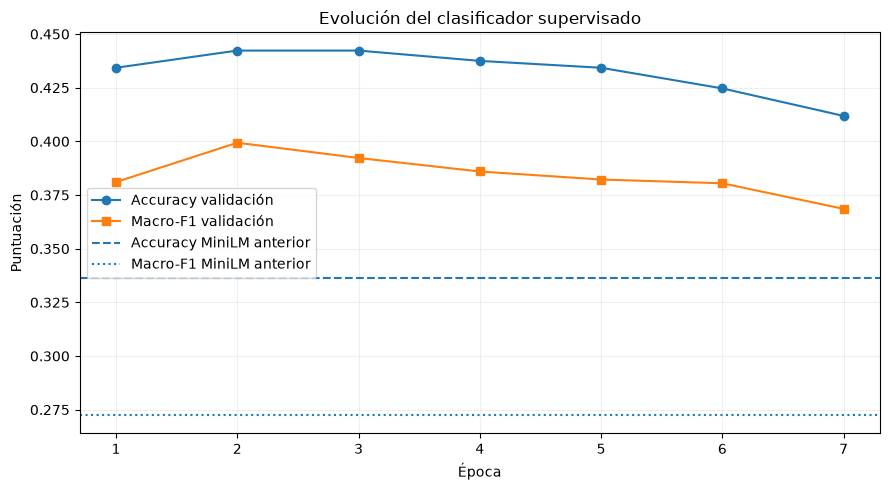

In [6]:
import matplotlib.pyplot as plt

epocas = range(1, len(historial["loss"]) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epocas,
    historial["accuracy_val"],
    label="Accuracy validación",
    marker="o"
)

plt.plot(
    epocas,
    historial["f1_val"],
    label="Macro-F1 validación",
    marker="s"
)

plt.axhline(
    y=0.3365,
    linestyle="--",
    label="Accuracy MiniLM anterior"
)

plt.axhline(
    y=0.2724,
    linestyle=":",
    label="Macro-F1 MiniLM anterior"
)

plt.xlabel("Época")
plt.ylabel("Puntuación")
plt.title("Evolución del clasificador supervisado")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [7]:
from pathlib import Path
import torch
import joblib

# Crear carpeta para guardar modelos
carpeta_modelos = Path("models")
carpeta_modelos.mkdir(exist_ok=True)

# Guardar los pesos del clasificador
torch.save(
    clasificador.state_dict(),
    carpeta_modelos / "clasificador_sst.pth"
)

# Guardar el codificador de categorías
joblib.dump(
    encoder,
    carpeta_modelos / "encoder_categorias.pkl"
)

print("Clasificador guardado correctamente")
print("Categorías:", len(encoder.classes_))

Clasificador guardado correctamente
Categorías: 12


REPORTE DEL CLASIFICADOR SUPERVISADO

                                                    precision    recall  f1-score   support

                             Condiciones locativas       0.78      0.13      0.23        52
                         Control documental SG-SST       0.94      0.98      0.96        52
                  Elementos de proteccion personal       0.93      0.75      0.83        52
                      Formacion y competencias SST       0.02      0.04      0.02        52
                       Gestion SST de contratistas       0.97      0.54      0.69        52
                    Gestion de sustancias quimicas       0.56      0.94      0.70        52
Identificacion de peligros y valoracion de riesgos       0.00      0.00      0.00        52
                      Inspecciones y mantenimiento       0.00      0.00      0.00        52
          Investigacion de incidentes y accidentes       0.63      0.98      0.77        52
             Preparacion y respuesta a em

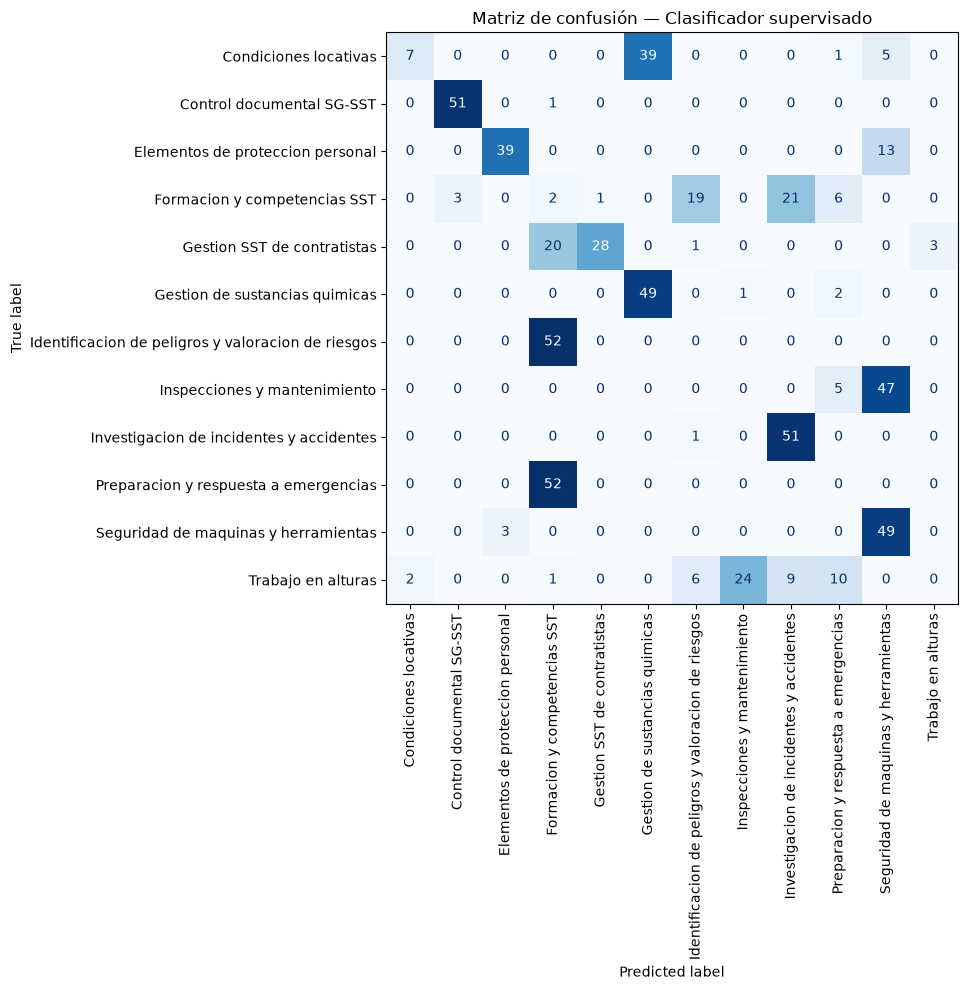

In [8]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Poner el clasificador en modo evaluación
clasificador.eval()

with torch.no_grad():
    salidas = clasificador(
        X_val_tensor.to(device)
    )

    predicciones = torch.argmax(
        salidas,
        dim=1
    ).cpu().numpy()

# Generar reporte
print("REPORTE DEL CLASIFICADOR SUPERVISADO\n")

print(
    classification_report(
        y_val,
        predicciones,
        target_names=encoder.classes_,
        zero_division=0
    )
)

# Matriz de confusión
matriz = confusion_matrix(
    y_val,
    predicciones
)

fig, ax = plt.subplots(figsize=(13, 10))

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=encoder.classes_
)

visualizacion.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

plt.title("Matriz de confusión — Clasificador supervisado")
plt.tight_layout()
plt.show()